In [ ]:
import shutil

total, used, free = shutil.disk_usage("/content")

print("Total storage:", round(total / (1024**3), 2), "GB")
print("Used storage:", round(used / (1024**3), 2), "GB")
print("Free storage:", round(free / (1024**3), 2), "GB")

Total storage: 107.72 GB
Used storage: 0.08 GB
Free storage: 107.62 GB



### 1. Mount Google Drive
Connect Google Colab to Google Drive so that the dataset and processed files can be stored permanently instead of relying on temporary Colab storage.


In [ ]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive



### 2. Create Project Directories
Create the main project folder and subfolders to organize the selected videos, extracted frames, processed faces and metadata files.


In [ ]:

import os

project_folder = "/content/drive/MyDrive/Deepfake_Project"

os.makedirs(project_folder, exist_ok=True)

print("Project folder ready:", project_folder)


Project folder ready: /content/drive/MyDrive/Deepfake_Project



### 3. Download Celeb-DF v2 Dataset
Download the Celeb-DF v2 dataset archive into the Colab runtime for accessing the original videos.


In [ ]:

!pip install -q gdown

import gdown
import os

file_id = "1iLx76wsbi9itnkxSqz9BVBl4ZvnbIazj"
output = "/content/CelebDFv2.zip"

gdown.download(
    id=file_id,
    output=output,
    quiet=False
)

print("\nDownload completed!")
print("File exists:", os.path.exists(output))

if os.path.exists(output):
    print("File size:", round(os.path.getsize(output) / (1024**3), 2), "GB")


Downloading...
From (original): https://drive.google.com/uc?id=1iLx76wsbi9itnkxSqz9BVBl4ZvnbIazj
From (redirected): https://drive.google.com/uc?id=1iLx76wsbi9itnkxSqz9BVBl4ZvnbIazj&confirm=t&uuid=a556f509-5d21-4abd-bd50-038448c2ec1b
To: /content/CelebDFv2.zip
100%|██████████| 9.95G/9.95G [02:04<00:00, 80.2MB/s]


Download completed!
File exists: True
File size: 9.27 GB



### 4. Verify Dataset Archive
Check whether the downloaded ZIP file exists, its size and whether it is a valid ZIP archive.


In [ ]:
import os
import zipfile

path = "/content/CelebDFv2.zip"

print("File exists:", os.path.exists(path))
print("File size:", os.path.getsize(path), "bytes")
print("Is it a valid ZIP?", zipfile.is_zipfile(path))

with open(path, "rb") as f:
    print("First 200 characters:")
    print(f.read(200))

File exists: True
File size: 9952957051 bytes
Is it a valid ZIP? True
First 200 characters:
b'PK\x03\x04\x14\x03\x00\x00\x00\x00TRoO\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x0b\x00\x00\x00Celeb-real/PK\x03\x04\x14\x03\x00\x00\x08\x00\x92\xb27O\x03&7\x01\x14F#\x00o\xc8#\x00\x17\x00\x00\x00Celeb-real/id0_0000.mp4L[\x078[Q\xd8\x16#\x82\xd8+\xf6,m\xd1\x86\xaa\xbd7\xb5\x8a\xd6,\xb1KE(Uj\x8b\xa2j\xd6.j\xb5\x94VkF\xa9\x91\xd8\xb5G[#\xb5\xb7\xda3j\xfd\xd7\xbf\x9f\xe7z$_\xbes\xee\x11\xf7|\xe7=\xef\xfb\x1e"""N\x17\xdf\x00/7\x1f\x14\x92\x88\x88\x98\xe8\xea7\xf0#\x81\xf4\x92\x14\x07>\x83\xb8<uv&\x12h'



### Explore Dataset Structure
Examine the ZIP archive and count the real and fake videos available in the Celeb-DF v2 dataset folders.

In [ ]:

import zipfile

zip_path = "/content/CelebDFv2.zip"

with zipfile.ZipFile(zip_path, 'r') as z:
    files = z.namelist()

    real_count = sum(
        1 for f in files
        if f.startswith("Celeb-real/") and f.lower().endswith(".mp4")
    )

    fake_count = sum(
        1 for f in files
        if f.startswith("Celeb-synthesis/") and f.lower().endswith(".mp4")
    )

    youtube_count = sum(
        1 for f in files
        if f.startswith("YouTube-real/") and f.lower().endswith(".mp4")
    )

print("Celeb-real:", real_count)
print("Celeb-synthesis:", fake_count)
print("YouTube-real:", youtube_count)
print("Total:", real_count + fake_count + youtube_count)


Celeb-real: 590
Celeb-synthesis: 5639
YouTube-real: 300
Total: 6529



### Select Initial Balanced Video Subset
Randomly select 100 real videos and 100 fake videos from the dataset. This balanced subset is used for initial development and testing of the preprocessing pipeline.


In [ ]:

import zipfile
import random
import os

zip_path = "/content/CelebDFv2.zip"
output_folder = "/content/drive/MyDrive/Deepfake_Project/selected_videos"

os.makedirs(output_folder, exist_ok=True)

random.seed(42)

with zipfile.ZipFile(zip_path, 'r') as z:

    real_videos = [
        f for f in z.namelist()
        if f.startswith("Celeb-real/") and f.lower().endswith(".mp4")
    ]

    fake_videos = [
        f for f in z.namelist()
        if f.startswith("Celeb-synthesis/") and f.lower().endswith(".mp4")
    ]

    selected_real = random.sample(real_videos, 100)
    selected_fake = random.sample(fake_videos, 100)

    selected_videos = selected_real + selected_fake

    for i, video in enumerate(selected_videos, 1):
        z.extract(video, output_folder)

        if i % 20 == 0:
            print(f"Extracted {i}/200 videos")

print("\nExtraction completed!")
print("Real videos:", len(selected_real))
print("Fake videos:", len(selected_fake))
print("Saved in:", output_folder)



Extracted 20/200 videos
Extracted 40/200 videos
Extracted 60/200 videos
Extracted 80/200 videos
Extracted 100/200 videos
Extracted 120/200 videos
Extracted 140/200 videos
Extracted 160/200 videos
Extracted 180/200 videos
Extracted 200/200 videos

Extraction completed!
Real videos: 100
Fake videos: 100
Saved in: /content/drive/MyDrive/Deepfake_Project/selected_videos



### Extract Video Frames Using OpenCV
Read the selected videos frame by frame using OpenCV and save one frame after every 30 frames. Store the extracted images in separate real and fake folders and generate a CSV file containing frame metadata.


In [ ]:

!pip install -q opencv-python

import cv2
import os
import pandas as pd
from tqdm import tqdm

input_folder = "/content/drive/MyDrive/Deepfake_Project/selected_videos"
output_folder = "/content/drive/MyDrive/Deepfake_Project/extracted_frames"

os.makedirs(output_folder, exist_ok=True)

metadata = []
failed_videos = 0
total_frames = 0

for label in ["Celeb-real", "Celeb-synthesis"]:

    label_name = "real" if label == "Celeb-real" else "fake"

    label_path = os.path.join(input_folder, label)

    for video_name in tqdm(os.listdir(label_path), desc=f"Processing {label_name}"):

        video_path = os.path.join(label_path, video_name)

        cap = cv2.VideoCapture(video_path)

        if not cap.isOpened():
            failed_videos += 1
            continue

        video_output = os.path.join(
            output_folder, label_name, video_name
        )
        os.makedirs(video_output, exist_ok=True)

        frame_number = 0
        saved_count = 0

        while True:
            success, frame = cap.read()

            if not success:
                break

            if frame_number % 30 == 0:
                frame_name = f"frame_{frame_number}.jpg"
                frame_path = os.path.join(video_output, frame_name)

                if cv2.imwrite(frame_path, frame):
                    metadata.append({
                        "label": label_name,
                        "video_name": video_name,
                        "frame_number": frame_number,
                        "frame_path": frame_path
                    })

                    saved_count += 1
                    total_frames += 1

            frame_number += 1

        cap.release()

        if saved_count == 0:
            failed_videos += 1

df = pd.DataFrame(metadata)

csv_path = "/content/drive/MyDrive/Deepfake_Project/frame_metadata.csv"
df.to_csv(csv_path, index=False)

print("\nFRAME EXTRACTION COMPLETED")
print("Videos processed:", 200 - failed_videos)
print("Frames extracted:", total_frames)
print("Failed videos:", failed_videos)
print("Metadata saved:", csv_path)


Processing fake: 100%|██████████| 100/100 [01:04<00:00,  1.56it/s]


FRAME EXTRACTION COMPLETED
Videos processed: 200
Frames extracted: 2606
Failed videos: 0
Metadata saved: /content/drive/MyDrive/Deepfake_Project/frame_metadata.csv



### Test MTCNN Face Detection
Apply MTCNN to a sample extracted frame to check whether a face can be detected, cropped, and resized to 224 × 224 pixels.


In [ ]:
!pip install -q mtcnn tensorflow

Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.
Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.
Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.


Faces detected: 1


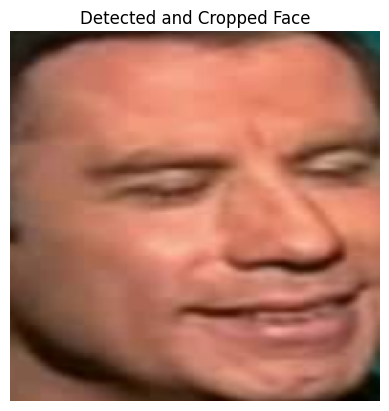

In [ ]:
from mtcnn import MTCNN
import cv2
import matplotlib.pyplot as plt

detector = MTCNN()

# Select one frame for testing
sample_path = df.iloc[0]["frame_path"]

image = cv2.imread(sample_path)
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

faces = detector.detect_faces(image_rgb)

print("Faces detected:", len(faces))

if len(faces) > 0:
    x, y, w, h = faces[0]["box"]

    x, y = max(0, x), max(0, y)

    face = image_rgb[y:y+h, x:x+w]
    face_resized = cv2.resize(face, (224, 224))

    plt.imshow(face_resized)
    plt.axis("off")
    plt.title("Detected and Cropped Face")
    plt.show()


### Extract and Preprocess Faces
Use MTCNN to detect faces in the extracted frames. Select the face with the highest confidence, crop it, resize it to 224 × 224 pixels, and save the processed images. Generate a CSV file containing the processed face metadata.


In [ ]:

import os
import cv2
import pandas as pd
from tqdm import tqdm

input_folder = "/content/drive/MyDrive/Deepfake_Project/extracted_frames"

output_folder = "/content/drive/MyDrive/Deepfake_Project/processed_faces"

os.makedirs(output_folder, exist_ok=True)

processed_metadata = []
no_face_count = 0
failed_count = 0

for label in ["real", "fake"]:

    label_path = os.path.join(input_folder, label)
    print(f"\nProcessing {label} faces...")

    for video_name in tqdm(os.listdir(label_path)):

        video_folder = os.path.join(label_path, video_name)

        if not os.path.isdir(video_folder):
            continue

        output_video_folder = os.path.join(
            output_folder, label, video_name
        )
        os.makedirs(output_video_folder, exist_ok=True)

        for frame_name in os.listdir(video_folder):

            if not frame_name.lower().endswith(".jpg"):
                continue

            frame_path = os.path.join(video_folder, frame_name)

            try:
                image = cv2.imread(frame_path)

                if image is None:
                    failed_count += 1
                    continue

                image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

                faces = detector.detect_faces(image_rgb)

                if len(faces) == 0:
                    no_face_count += 1
                    continue

                best_face = max(
                    faces, key=lambda face: face["confidence"]
                )

                x, y, w, h = best_face["box"]

                x1 = max(0, x)
                y1 = max(0, y)
                x2 = min(image_rgb.shape[1], x + w)
                y2 = min(image_rgb.shape[0], y + h)

                face_crop = image_rgb[y1:y2, x1:x2]

                if face_crop.size == 0:
                    failed_count += 1
                    continue

                resized_face = cv2.resize(
                    face_crop, (224, 224)
                )

                save_path = os.path.join(
                    output_video_folder, frame_name
                )

                face_bgr = cv2.cvtColor(
                    resized_face, cv2.COLOR_RGB2BGR
                )

                if cv2.imwrite(save_path, face_bgr):

                    processed_metadata.append({
                        "label": label,
                        "video_name": video_name,
                        "frame_name": frame_name,
                        "face_path": save_path
                    })
                else:
                    failed_count += 1

            except Exception as e:
                failed_count += 1

processed_df = pd.DataFrame(processed_metadata)

csv_path = "/content/drive/MyDrive/Deepfake_Project/processed_faces_metadata.csv"

processed_df.to_csv(csv_path, index=False)

print("\nFACE PREPROCESSING COMPLETED")
print("Successfully processed:", len(processed_df))
print("No face detected:", no_face_count)
print("Failed:", failed_count)
print("Metadata saved:", csv_path)



Processing real faces...


100%|██████████| 100/100 [10:10<00:00,  6.10s/it]



Processing fake faces...


100%|██████████| 100/100 [09:53<00:00,  5.94s/it]


FACE PREPROCESSING COMPLETED
Successfully processed: 2606
No face detected: 0
Failed: 0
Metadata saved: /content/drive/MyDrive/Deepfake_Project/processed_faces_metadata.csv


### Visualize Processed Real and Fake Faces
Display sample face images from both real and fake categories to visually inspect the output of the preprocessing pipeline and verify that faces have been detected and cropped correctly.


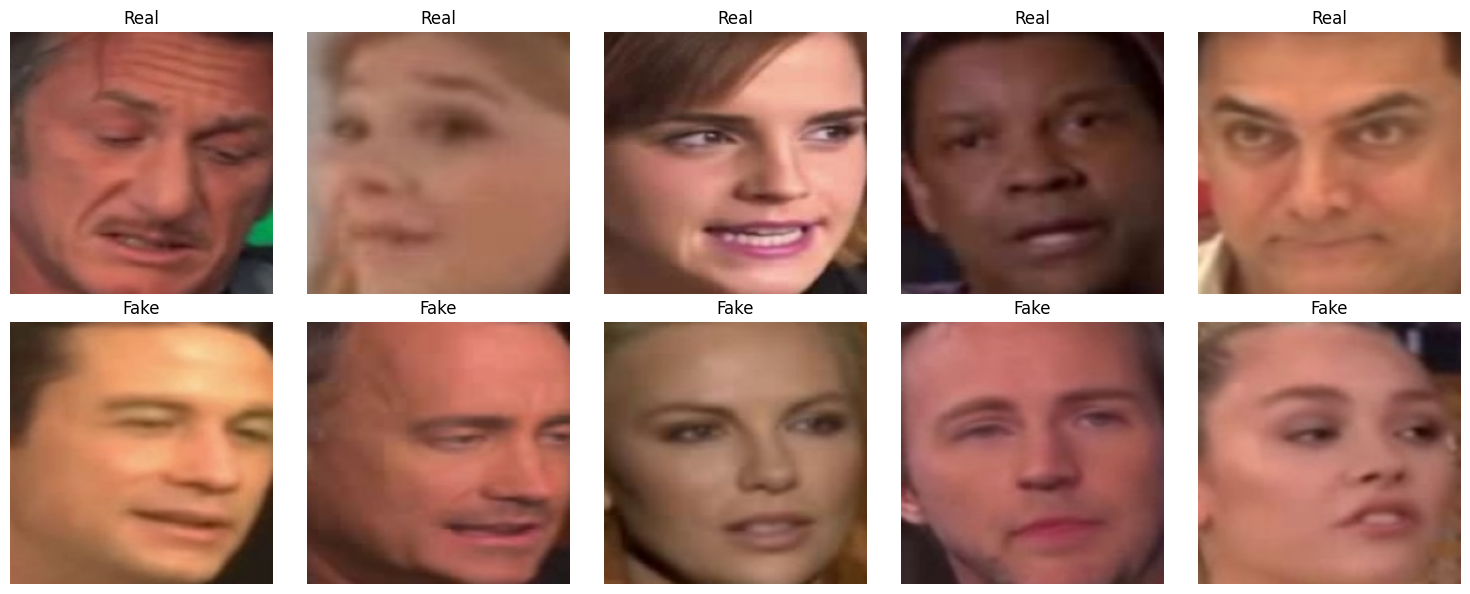

In [5]:
import matplotlib.pyplot as plt
import os
import random
from PIL import Image

base_path = "/content/drive/MyDrive/Deepfake_Project/processed_faces"

def get_sample_images(category, count=5):
    category_path = os.path.join(base_path, category)
    images = []

    video_folders = os.listdir(category_path)
    selected_videos = random.sample(video_folders, count)

    for video in selected_videos:
        video_path = os.path.join(category_path, video)
        image_files = os.listdir(video_path)

        if image_files:
            image_path = os.path.join(video_path, random.choice(image_files))
            images.append(image_path)

    return images

real_images = get_sample_images("real")
fake_images = get_sample_images("fake")

fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for i, img_path in enumerate(real_images):
    axes[0, i].imshow(Image.open(img_path))
    axes[0, i].set_title("Real")
    axes[0, i].axis("off")

for i, img_path in enumerate(fake_images):
    axes[1, i].imshow(Image.open(img_path))
    axes[1, i].set_title("Fake")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()